In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import LinearSegmentedColormap

# Exploração inicial dos dados

In [ ]:
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")

df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [10]:
df.shape

(114000, 20)

In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(113550, 20)

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,113550.0,33.324139,22.283976,0.000,17.00000,35.000000,50.000000,100.000
duration_ms,113550.0,228079.362202,106414.782554,0.000,174180.25000,213000.000000,261587.750000,5237295.000
danceability,113550.0,0.567031,0.173408,0.000,0.45600,0.580000,0.695000,0.985
energy,113550.0,0.642090,0.251052,0.000,0.47300,0.685000,0.854000,1.000
key,113550.0,5.309467,3.560134,0.000,2.00000,5.000000,8.000000,11.000
loudness,113550.0,-8.243419,5.011401,-49.531,-9.99775,-6.997000,-5.001000,4.532
mode,113550.0,0.637860,0.480621,0.000,0.00000,1.000000,1.000000,1.000
speechiness,113550.0,0.084674,0.105761,0.000,0.03590,0.048900,0.084500,0.965
acousticness,113550.0,0.314067,0.331907,0.000,0.01680,0.168000,0.596000,0.996
instrumentalness,113550.0,0.155702,0.309216,0.000,0.00000,0.000041,0.048675,1.000


In [14]:
df.isnull().sum()

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

<Axes: >

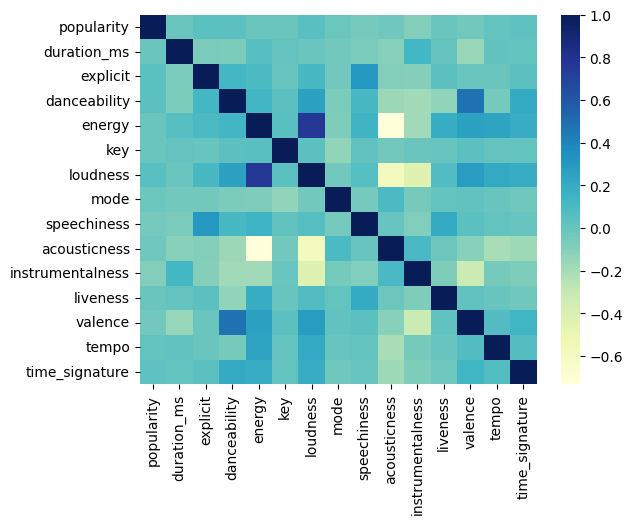

In [15]:
matriz_correlacao = df.corr(numeric_only=True)
sns.heatmap(matriz_correlacao, annot=False, cmap='YlGnBu')

In [16]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature"
]

df[features].corr().round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
danceability,1.00,0.13,0.26,0.11,-0.17,-0.18,-0.13,0.48,-0.05,0.21
energy,0.13,1.00,0.76,0.14,-0.73,-0.18,0.18,0.26,0.25,0.19
loudness,0.26,0.76,1.00,0.06,-0.59,-0.43,0.08,0.28,0.21,0.19
speechiness,0.11,0.14,0.06,1.00,-0.00,-0.09,0.21,0.04,0.02,-0.00
acousticness,-0.17,-0.73,-0.59,-0.00,1.00,0.10,-0.02,-0.11,-0.21,-0.18
instrumentalness,-0.18,-0.18,-0.43,-0.09,0.10,1.00,-0.08,-0.32,-0.05,-0.08
liveness,-0.13,0.18,0.08,0.21,-0.02,-0.08,1.00,0.02,0.00,-0.02
valence,0.48,0.26,0.28,0.04,-0.11,-0.32,0.02,1.00,0.08,0.13
tempo,-0.05,0.25,0.21,0.02,-0.21,-0.05,0.00,0.08,1.00,0.07
time_signature,0.21,0.19,0.19,-0.00,-0.18,-0.08,-0.02,0.13,0.07,1.00


## Verificando graficamente o padrão das features

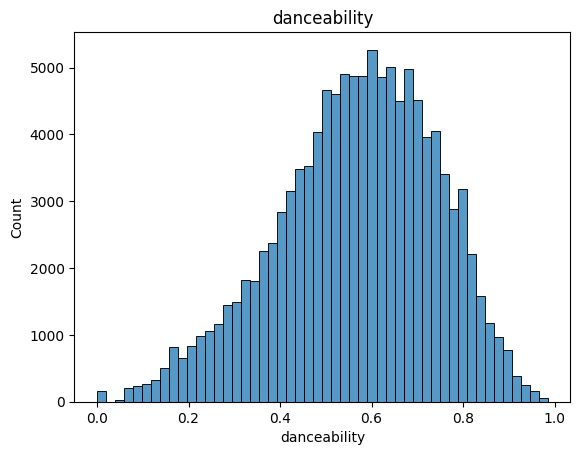

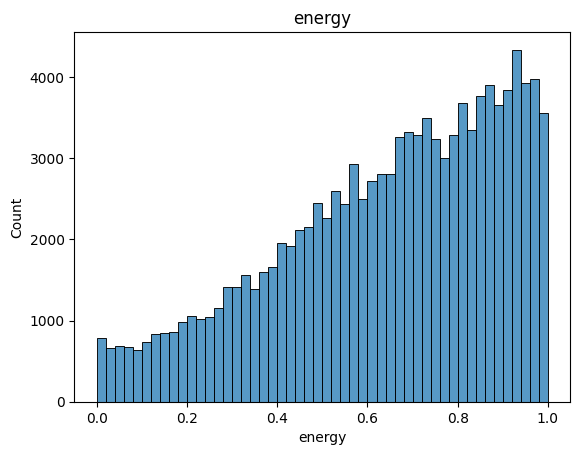

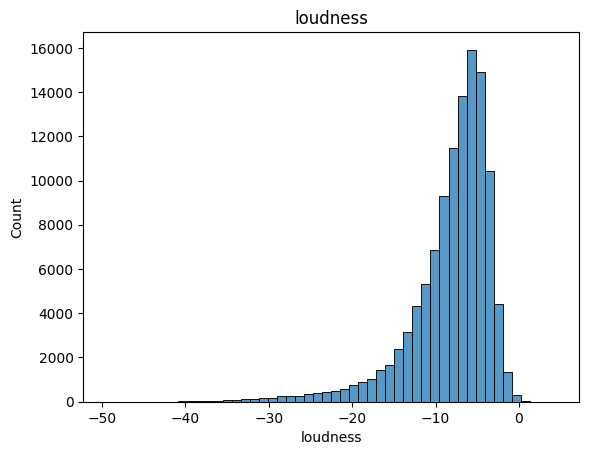

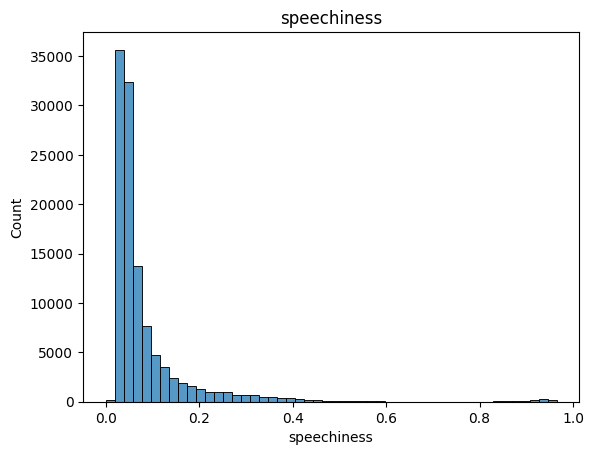

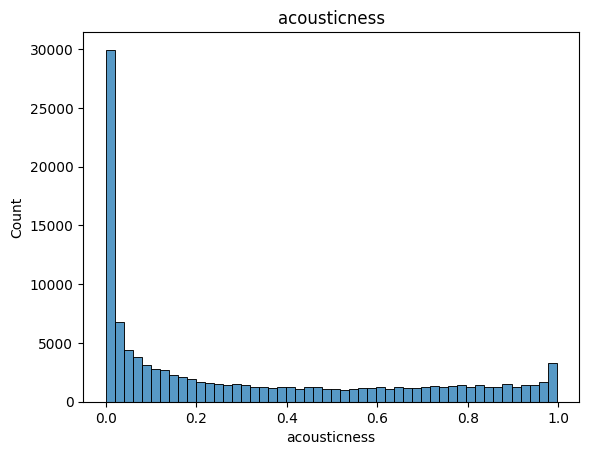

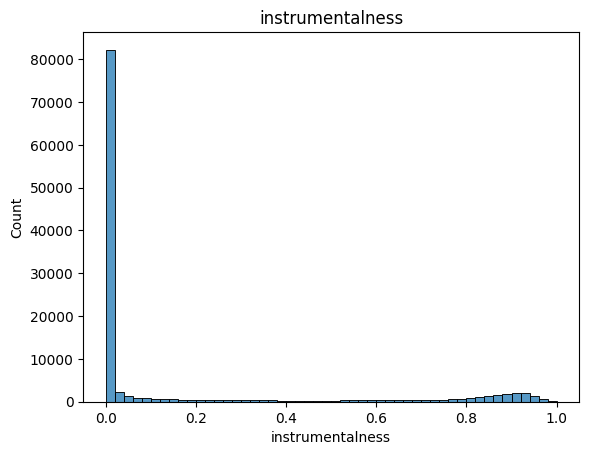

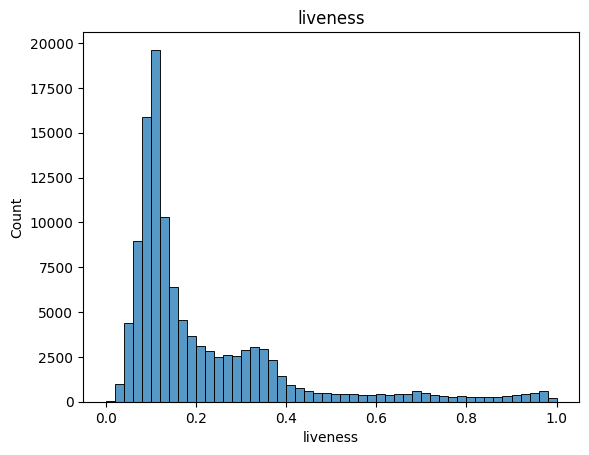

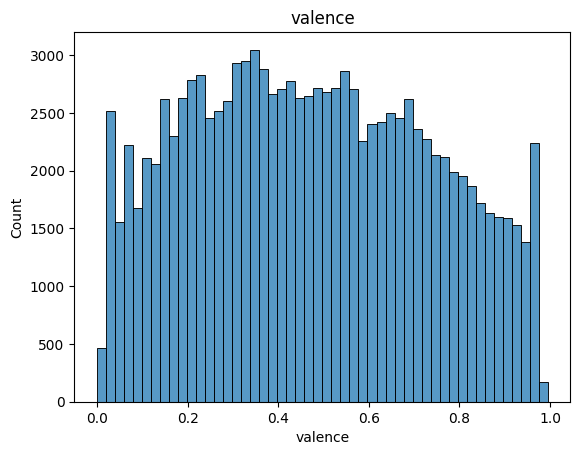

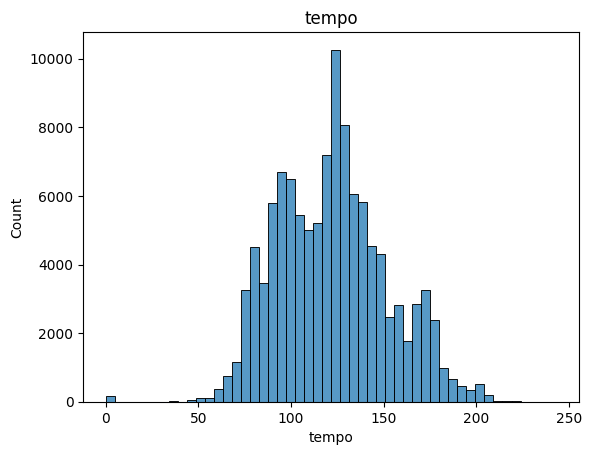

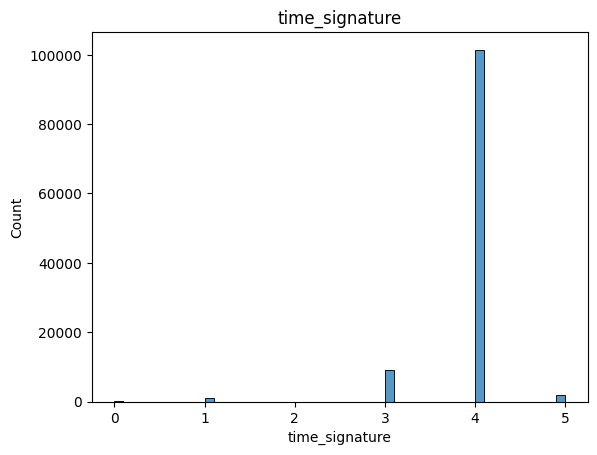

In [17]:
for feature in features:
    sns.histplot(df[feature], bins=50)
    plt.title(feature)
    plt.show()

## Exclusão de features após análise gráfica

In [18]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]

## Análise prévia dos gêneros

In [19]:
genre_profile = (
    df.groupby("track_genre")[features]
      .median()
      .T
)

genre_profile

track_genre,acoustic,afrobeat,alt-rock,alternative,ambient,anime,black-metal,bluegrass,blues,brazil,...,spanish,study,swedish,synth-pop,tango,techno,trance,trip-hop,turkish,world-music
danceability,0.558500,0.69100,0.543000,0.560000,0.3640,0.536000,0.282000,0.544000,0.579000,0.5630,...,0.6150,0.6955,0.601000,0.629000,0.532000,0.69900,0.58900,0.6440,0.633000,0.4230
energy,0.394500,0.72700,0.800000,0.745000,0.1780,0.774000,0.937000,0.542000,0.584500,0.6255,...,0.7345,0.3970,0.658000,0.734000,0.368500,0.77350,0.87900,0.6250,0.620000,0.5500
loudness,-9.003000,-7.32400,-5.846000,-5.711000,-18.0410,-5.825000,-6.032000,-9.314500,-7.858000,-7.2835,...,-5.9805,-10.3195,-6.964000,-7.846000,-9.748500,-8.00200,-6.21100,-8.9300,-7.823000,-7.6300
speechiness,0.035200,0.05460,0.042000,0.048700,0.0375,0.053600,0.075200,0.032900,0.043050,0.0419,...,0.0503,0.0657,0.040500,0.037750,0.053350,0.04935,0.05360,0.0443,0.055800,0.0343
acousticness,0.691500,0.18200,0.025900,0.037200,0.9210,0.089900,0.000045,0.598000,0.343000,0.2765,...,0.1755,0.5705,0.192000,0.072050,0.884000,0.01220,0.00645,0.1250,0.250000,0.1270
instrumentalness,0.000003,0.00837,0.000069,0.000008,0.8750,0.000008,0.434000,0.000712,0.000022,0.0000,...,0.0000,0.8670,0.000003,0.000682,0.000236,0.73700,0.45200,0.2560,0.000003,0.0000
valence,0.374000,0.73000,0.525000,0.484000,0.1250,0.434000,0.152000,0.665000,0.639000,0.4340,...,0.5490,0.3860,0.530000,0.624500,0.597500,0.25700,0.22600,0.4710,0.449000,0.2080
tempo,117.751500,115.80200,124.980000,121.907000,111.8510,124.061000,128.049000,124.995500,114.543000,126.0165,...,122.1050,92.2310,120.043000,121.011000,116.683500,125.02050,134.95800,115.0320,119.884000,129.8160


<Axes: xlabel='track_genre'>

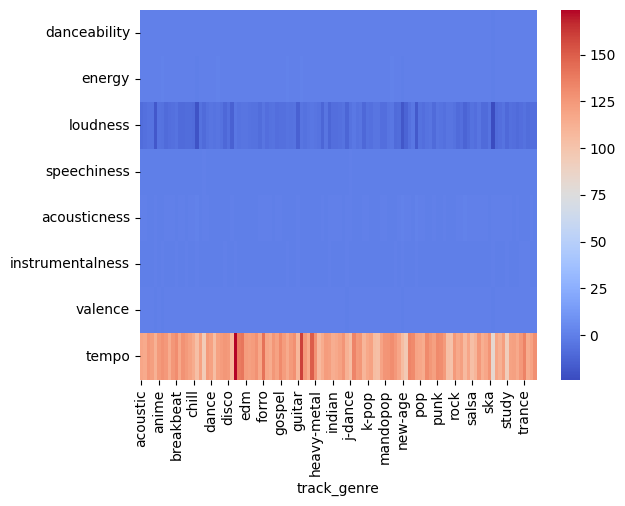

In [20]:
sns.heatmap(genre_profile, cmap='coolwarm')

In [21]:
scaler = StandardScaler()

df_scaled = df.copy()

df_scaled[features] = scaler.fit_transform(df[features])

In [22]:
genre_profile_scaled = (
    df_scaled
    .groupby("track_genre")[features]
    .median()
    .T
)

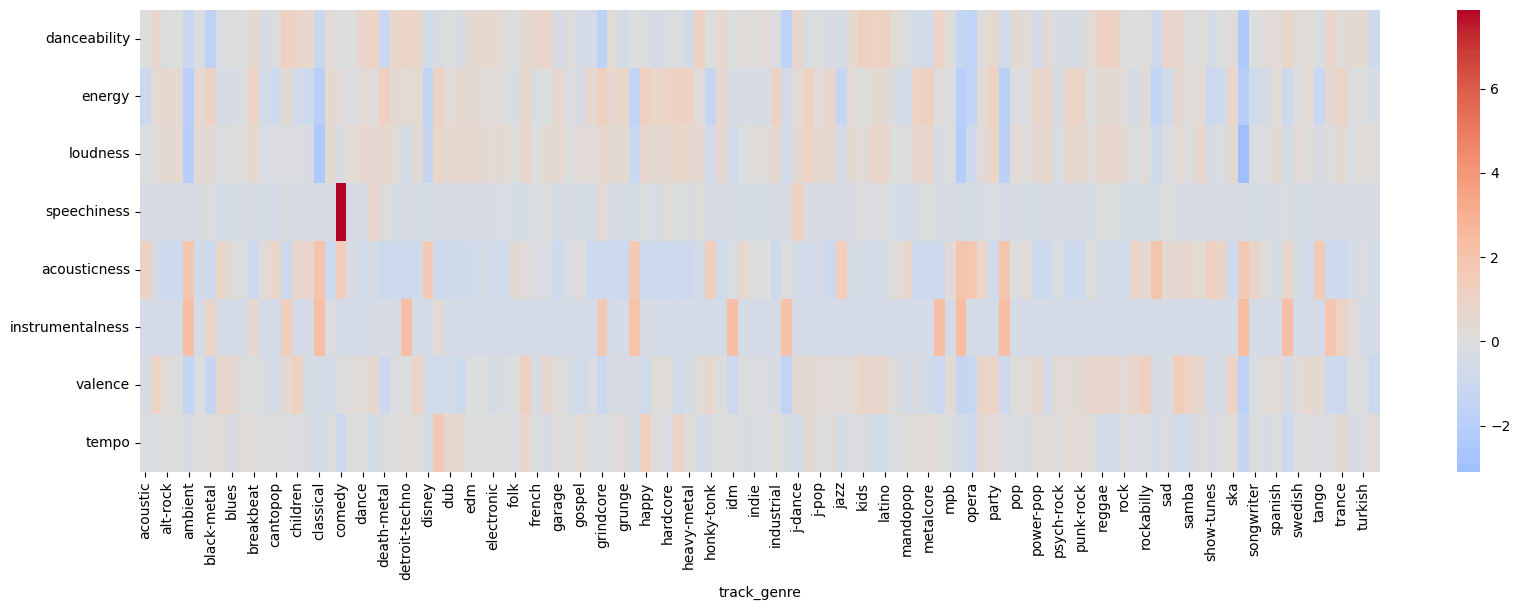

In [23]:
plt.figure(figsize=(20, 6))

sns.heatmap(
    genre_profile_scaled,
    cmap="coolwarm",
    center=0
)

plt.show()

In [24]:
df[df["track_genre"] == "comedy"][
    ["track_name", "artists", "speechiness"]
].sort_values("speechiness", ascending=False).head(30)

,track_name,artists,speechiness
18152,turd whistle,Tenacious D,0.965
18530,Less and Less Radical,Patton Oswalt,0.963
18504,The Real World,Tom Papa,0.963
18432,Chemotherapy,Robert Schimmel,0.962
18674,Morning Tom,Tom Papa,0.962
18227,Parents and Pills,Patton Oswalt,0.962
18137,Get Rid of That Joke!,Dan Cummins,0.962
18666,Angry Young Men,Tom Papa,0.962
18663,The Human Contract,Tom Papa,0.962
18739,Christmas is My Favorite,Larry The Cable Guy,0.961


In [25]:
df.groupby("track_genre")["speechiness"].median().sort_values()

track_genre
honky-tonk    0.0322
cantopop      0.0328
bluegrass     0.0329
mandopop      0.0330
country       0.0336
               ...  
hardcore      0.1060
grindcore     0.1230
dancehall     0.1560
j-dance       0.2200
comedy        0.9170
Name: speechiness, Length: 114, dtype: float64

Vou excluir o "comedy" pois o mesmo não é um gênero músical e está deformando o heatmap

In [26]:
df = df[df["track_genre"] != "comedy"].copy()

In [27]:
df_scaled = df.copy()

df_scaled[features] = scaler.fit_transform(df[features])

In [28]:
genre_profile_scaled = (
    df_scaled
    .groupby("track_genre")[features]
    .median()
    .T
)

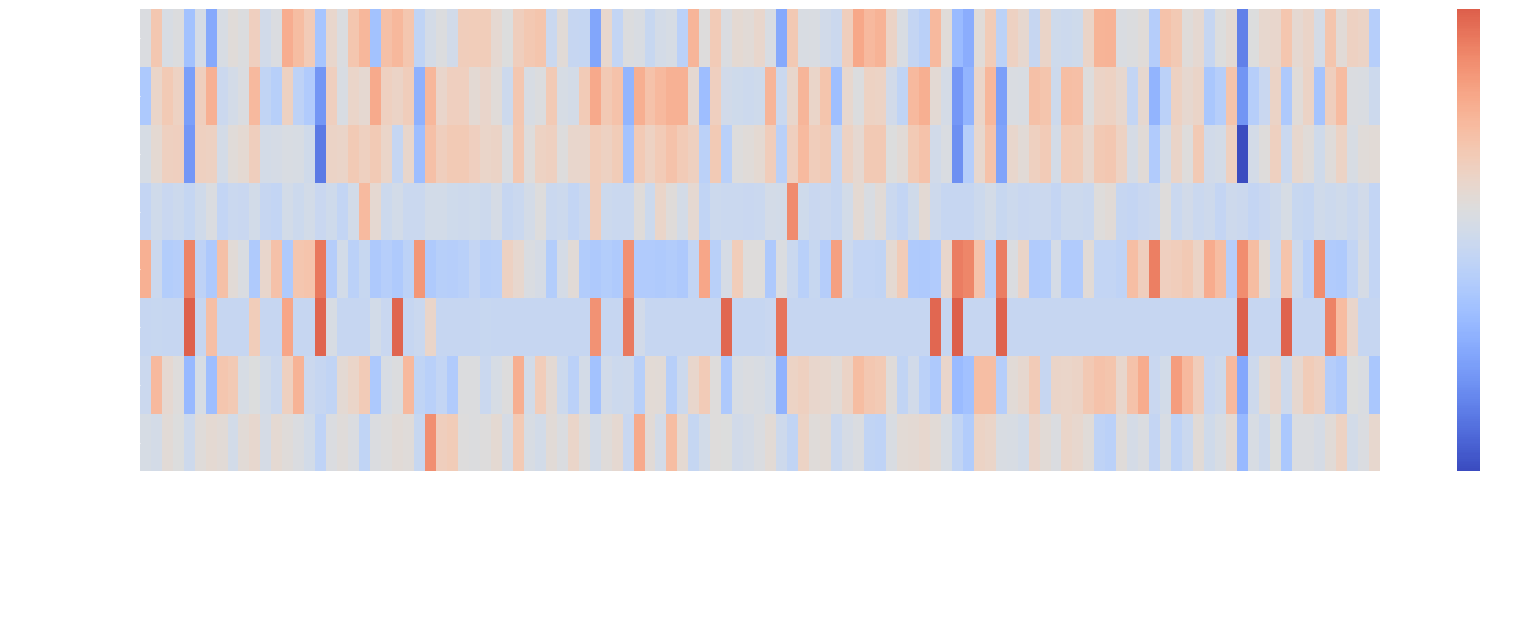

In [29]:
plt.figure(figsize=(20, 6))

ax = sns.heatmap(
    genre_profile_scaled,
    cmap="coolwarm",
    center=0
)

# White text for the dark PowerPoint background
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")

# White text on the colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(colors="white")


plt.savefig(
    "../heatmap_genres.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()

<Axes: xlabel='track_genre'>

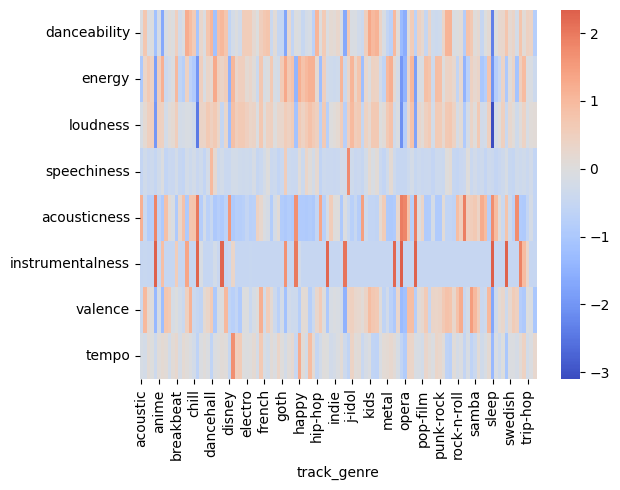

In [30]:
pitch_cmap = LinearSegmentedColormap.from_list(
    "pitch",
    ["#6F9BFF", "#161E2B", "#50DC91"]
)

sns.heatmap(
    genre_profile_scaled,
    cmap="coolwarm",
    center=0
)

In [31]:
df_scaled.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.627214,-0.718033,1,0.295020,0,0.801071,-0.842024,-0.506310,0.3580,0.927062,-1.151353,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,-0.845051,-1.891037,1,-1.798812,1,-0.030368,1.856999,-0.506296,0.1010,-0.798976,-1.499899,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,-0.741533,-1.123614,0,-0.301449,1,-0.287154,-0.303914,-0.506313,0.1170,-1.365332,-1.538571,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,-1.730711,-2.314113,0,-2.054327,1,-0.528981,1.799496,-0.506086,0.1320,-1.276718,1.984590,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.293654,-0.789606,2,-0.290869,1,-0.325796,0.479947,-0.506313,0.0829,-1.184252,-0.080714,4,acoustic


In [32]:
df_scaled_usable = df_scaled[[
    "track_id",
    "artists",
    "track_name",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]]

In [33]:
df_scaled_usable

,track_id,artists,track_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,0.627214,-0.718033,0.295020,0.801071,-0.842024,-0.506310,0.927062,-1.151353
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,-0.845051,-1.891037,-1.798812,-0.030368,1.856999,-0.506296,-0.798976,-1.499899
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,-0.741533,-1.123614,-0.301449,-0.287154,-0.303914,-0.506313,-1.365332,-1.538571
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,-1.730711,-2.314113,-2.054327,-0.528981,1.799496,-0.506086,-1.276718,1.984590
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,0.293654,-0.789606,-0.290869,-0.325796,0.479947,-0.506313,-1.184252,-0.080714
...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,Sleep My Little Boy,-2.271308,-1.616673,-1.630730,-0.455436,0.997476,2.484994,-1.697055,0.121367
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,Water Into Light,-2.259806,-2.085875,-2.015002,-0.481613,2.068853,2.639716,-1.692817,-1.240863
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Miss Perfumado,0.356916,-1.242902,-0.533210,-0.457929,1.684489,-0.506313,1.034939,0.334713
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Friends,0.115372,-0.539100,-0.532012,-0.611252,0.213616,-0.506313,-0.236472,0.454438


In [34]:
df["track_id"].duplicated().sum()

np.int64(23802)

In [35]:
df.groupby("track_id")["track_genre"].nunique().sort_values(ascending=False).head(10)

track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2Ey6v4Sekh3Z0RUSISRosD    8
2kkvB3RNRzwjFdGhaUA0tz    8
2vU6bm5hVF2idVknGzqyPL    7
0e5LcankE0UyJUuCoq1uH2    7
08kTa3SL9sV6Iy8KLKtGql    7
6bzWr3EpSEolVwlbLk58il    7
5ftfVzSLIi5ZxYdNbRtf41    7
7tbzfR8ZvZzJEzy6v0d6el    7
2qgXrzJsry4KgYoJCpuaul    7
Name: track_genre, dtype: int64

In [36]:
df_scaled_usable.shape

(112554, 11)

In [37]:
df_scaled_usable = df_scaled_usable.drop_duplicates()

In [38]:
df_scaled_usable.shape

(88752, 11)

In [39]:
df.groupby("track_id")["track_genre"].nunique().value_counts().sort_index()

track_genre
1    72460
2    11417
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64

In [40]:
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "valence",
    "tempo"
]

inconsistent_tracks = (
    df.groupby("track_id")[features]
    .nunique()
    .gt(1)
    .any(axis=1)
)

print("IDs com features inconsistentes:", inconsistent_tracks.sum())

IDs com features inconsistentes: 0


In [41]:
df_scaled_usable

,track_id,artists,track_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,0.627214,-0.718033,0.295020,0.801071,-0.842024,-0.506310,0.927062,-1.151353
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,-0.845051,-1.891037,-1.798812,-0.030368,1.856999,-0.506296,-0.798976,-1.499899
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,-0.741533,-1.123614,-0.301449,-0.287154,-0.303914,-0.506313,-1.365332,-1.538571
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,-1.730711,-2.314113,-2.054327,-0.528981,1.799496,-0.506086,-1.276718,1.984590
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,0.293654,-0.789606,-0.290869,-0.325796,0.479947,-0.506313,-1.184252,-0.080714
...,...,...,...,...,...,...,...,...,...,...,...
113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,Sleep My Little Boy,-2.271308,-1.616673,-1.630730,-0.455436,0.997476,2.484994,-1.697055,0.121367
113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,Water Into Light,-2.259806,-2.085875,-2.015002,-0.481613,2.068853,2.639716,-1.692817,-1.240863
113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Miss Perfumado,0.356916,-1.242902,-0.533210,-0.457929,1.684489,-0.506313,1.034939,0.334713
113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Friends,0.115372,-0.539100,-0.532012,-0.611252,0.213616,-0.506313,-0.236472,0.454438


In [48]:
df_scaled_usable.isnull().sum()

track_id            0
artists             1
track_name          1
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
valence             0
tempo               0
dtype: int64

In [59]:
df_scaled_usable[df_scaled_usable["artists"].isnull()]

,track_id,artists,track_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,-0.379217,-0.232926,-0.246753,-0.22732,1.148801,-0.493549,1.000264,0.535692


In [60]:
df_scaled_usable.shape

(88752, 11)

In [63]:
df_scaled_usable = df_scaled_usable.drop(df_scaled_usable[df_scaled_usable["artists"].isnull()].index)

In [64]:
df_scaled_usable.shape

(88751, 11)